# POC 04 — three training schedules: all-months, commissioning, streaming

POC_02 v4 settled the preprocessing question: with **flow orientation** the global model
reconstructs (median window r 0.62 against 0.03), FedAvg stops costing shape (local − global
r ≈ 0.00), and other clients' local models transfer (`r_cross` 0.24–0.86). What it left
standing:

* the **drifting client** goes flat exactly in the months it drifts (A's pure `shape_amp`
  0.66 in init, 0.08 in transition, 0.06 in final);
* **bidirectional** mixed sensors stay weak;
* the weekly (weekend) modulation is missing from single-window reconstructions, so the
  prototypes cannot have it either — `ceiling` = `aligned` at r_shape 0.64;
* **every model has seen the whole horizon**, so describing month 20 uses months 21–64.

This notebook compares three schedules on the same world, selection, geometry and scaler:

| cell | schedule | what it means |
|---|---|---|
| `all` | none | the POC_02 setting: every month, every round |
| `comm` | `Schedule("commissioning", months=init)` | trained on the init months, then frozen; the rest is only encoded |
| `stream` | `Schedule("streaming", block_months=B, rounds_per_block=R)` | prequential: score the next block unseen, then train on it, carrying weights and prototypes |

Every POC_02 analysis is run on all three, and §8 asks the thesis question directly: which
schedule makes the drift most visible in the artifacts while leaving the other clients alone.

**Defaults carried over from v4:** `orient=True`, geometry `a3w84s4`, and the two objectives
that did best (`pw0` reconstruction-only, and `pw.1+s` with the spectral term, which was much
the best on the drifting client: r_pure 0.71 against 0.25).

## 0. Setup

In [1]:
import sys, pathlib, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch

REPO = next((p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
             if (p / "src" / "fedwater").is_dir()), None)
assert REPO is not None, "run this from inside the fedwater repo"
LAB_DIR = REPO / "notebooks" / "fedwater_lab_refactor"
for p in (REPO / "src", LAB_DIR):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

from fedwater_lab.worlds import load_world, pick_world
from fedwater_lab.store import Store
from fedwater_lab.specs import POC, Geometry, LossTerms, Schedule
from fedwater_lab.runner import run_cell
from fedwater_lab import data as D, recon as RC, train as T
from fedwater_lab import aligned as AL, winrec as WR, localeval as LE
from fedwater_lab import streaming as ST, compare as CP

EXPERIMENTS = REPO / "data" / "09_experiments"
pd.set_option("display.width", 220, "display.max_columns", 40)

REQUIRE_GPU = True
print(torch.__version__, torch.version.cuda, torch.cuda.is_available())
if REQUIRE_GPU:
    assert torch.cuda.is_available(), "no CUDA device visible to torch"

2.5.1+cu124 12.4 True


## 1. World, sensors, orientation

In [2]:
FILTERS = dict(sim_hash="0ed323104afb", placement_source="dynamic") #ece8f4ad92e5
world = load_world(pick_world(EXPERIMENTS, **FILTERS))
store = Store(LAB_DIR / "lab_sandbox")
print(world.summary()[["tag", "n_months", "init_months", "final_months",
                       "drift_district", "first_switch", "last_switch"]].to_string())

GEOM = Geometry(interval_agg_h=3, window_size=84, step_size=4)
BASE = POC.with_(kinds=("flow",), classes=("branch", "transit"), orient=True, geometry=GEOM)

OT = D.orientation_table(world, BASE)
display(OT.round(3))
display(D.channel_alignment(world, BASE))
AUDIT = store.audit(world.sim_hash)
if len(AUDIT) and not AUDIT["ok"].all():
    display(AUDIT[~AUDIT["ok"]])
    print("set PURGE below to remove these before training")
PURGE = False
if PURGE and len(AUDIT):
    print("purged:", store.purge(world.sim_hash, AUDIT.loc[~AUDIT["ok"], "run_key"]))

tag               District_C__LC_LR_LR_LC_LI__baseline
n_months                                            71
init_months                                      0..11
final_months                                    34..70
drift_district                              District_C
first_switch                                        12
last_switch                                         33


,client,slot,median_ref,sign,frac_rev_ref,frac_rev_all,bidirectional,sensor,kind,slot_class
0,District_A,q_branch_0,-1.679,-1.0,0.000,0.000,False,q_P633,flow,branch
1,District_A,q_branch_1,1.351,1.0,0.000,0.000,False,q_P781,flow,branch
2,District_A,q_transit_0,6.249,1.0,0.164,0.132,True,q_P995,flow,transit
3,District_A,q_transit_1,-0.943,-1.0,0.000,0.000,False,q_P981,flow,transit
4,District_B,q_branch_0,3.929,1.0,0.000,0.000,False,q_P1033,flow,branch
5,District_B,q_branch_1,1.142,1.0,0.000,0.000,False,q_P1024,flow,branch
6,District_B,q_transit_0,1.618,1.0,0.394,0.393,True,q_P341,flow,transit
7,District_B,q_transit_1,0.990,1.0,0.000,0.000,False,q_P142,flow,transit
8,District_C,q_branch_0,-2.265,-1.0,0.000,0.000,False,q_P5,flow,branch
9,District_C,q_branch_1,-1.541,-1.0,0.000,0.000,False,q_P295,flow,branch


client,District_A,District_B,District_C,District_D,District_E
channel,,,,,
0,q_branch_0 · · pnan · -,q_branch_0 · · pnan · +,q_branch_0 · · pnan · -,q_branch_0 · · pnan · +,q_branch_0 · · pnan · -
1,q_branch_1 · · pnan · +,q_branch_1 · · pnan · +,q_branch_1 · · pnan · -,q_branch_1 · · pnan · -,q_branch_1 · · pnan · -
2,q_transit_0 · · pnan · + · bidir,q_transit_0 · · pnan · + · bidir,q_transit_0 · · pnan · - · bidir,q_transit_0 · · pnan · + · bidir,q_transit_0 · · pnan · + · bidir
3,q_transit_1 · · pnan · -,q_transit_1 · · pnan · +,q_transit_1 · · pnan · + · bidir,q_transit_1 · · pnan · + · bidir,q_transit_1 · · pnan · + · bidir


## 2. The three schedules

**Equal budgets, not equal rounds.** A commissioning cell trains on the init months only and a
streaming cell on one block at a time, so the same `rounds` buys very different numbers of
optimiser steps. `ST.step_plan` reports the steps each spec will run, and
`ST.rounds_for_steps` picks rounds to hit a target. `TARGET_STEPS` is the common budget
(v4's `s4` cells ran about 2,850 steps per client).

**What carries across blocks in streaming:** the global weights, each client's local weights,
and the accumulated global prototypes (so the contrastive term of block *b* pulls towards
prototypes computed on earlier regimes — which is what makes a change show up as a pull away
from them). Adam moments restart per block, because the upstream trainer builds its
optimisers with its data.

The first block trains for `warm_rounds` so the model does not enter block 1 untrained.

In [3]:
TARGET_STEPS = 2850
INIT_LO, INIT_HI = world.phases()["init"][0], world.phases()["init"][1] - 1
BLOCK_MONTHS = 6

OBJ = {"pw0": LossTerms(proto_weight=0.0),
       "pw.1+s": LossTerms(proto_weight=0.1, spec=1.0)}

fw_all, _, fl_all = D.build_windows(world, BASE, cache=D.CACHE)
print({c: len(d["labels"]) for c, d in fw_all.items()}, "windows/client")

CELLS, PLAN = {}, []
for oname, lt in OBJ.items():
    base = BASE.with_(loss_terms=lt, **{"training.rounds": 30, "training.local_epochs": 5})
    cand = {
        "all": base,
        "comm": base.with_(schedule=Schedule(mode="commissioning",
                                             months=(INIT_LO, INIT_HI))),
        "stream": base.with_(schedule=Schedule(mode="streaming",
                                               block_months=BLOCK_MONTHS,
                                               rounds_per_block=5)),
    }
    # Match the step budget. `step_plan` must see the spec's OWN fl, because
    # local_epochs lives there: planning with the base fl (1 epoch) is what
    # made the first runs train 5x their target.
    flof = lambda sp: sp.as_fl(world.fl, reference_months=world.warmup_months)
    r_comm = ST.rounds_for_steps(cand["comm"], fw_all, flof(cand["comm"]), TARGET_STEPS)
    cand["comm"] = cand["comm"].with_(**{"training.rounds": r_comm})
    n_blocks = len(ST.month_blocks(range(world.n_months), BLOCK_MONTHS))
    r_str = ST.rounds_for_steps(cand["stream"], fw_all, flof(cand["stream"]),
                                TARGET_STEPS)
    cand["stream"] = cand["stream"].with_(
        schedule=Schedule(mode="streaming", block_months=BLOCK_MONTHS,
                          rounds_per_block=max(1, round(r_str / n_blocks)),
                          warm_rounds=10))
    for sname, sp in cand.items():
        key = f"{oname}·{sname}"
        CELLS[key] = sp
        PLAN.append({"cell": key, **ST.step_plan(sp, fw_all, flof(sp)),
                     "label": sp.label(), "in store": store.exists(world, sp)})

# every cell must land within ~20% of the budget, or the comparison is about
# training volume, not schedule
_p = pd.DataFrame(PLAN)
off = _p[(_p["steps"] < 0.8 * TARGET_STEPS) | (_p["steps"] > 1.2 * TARGET_STEPS)]
if len(off):
    print("OFF BUDGET (fix before reading §8):")
    display(off[["cell", "mode", "rounds", "steps"]])

display(_p.round(1))
TRAIN = list(CELLS)

{'District_A': 2262, 'District_B': 2262, 'District_C': 2262, 'District_D': 2262, 'District_E': 2262} windows/client
OFF BUDGET (fix before reading §8):


,cell,mode,rounds,steps
0,pw0·all,all,30,5400
3,pw.1+s·all,all,30,5400


,cell,mode,windows_per_pass,batches,rounds,steps,label,in store
0,pw0·all,all,2262.0,36,30,5400,fbt__none+or__minmax_ref__a3w84s4__u30r30e5s0_...,False
1,pw0·comm,C0-11,379.0,6,95,2850,fbt__none+or__minmax_ref__a3w84s4__u30r95e5s0_...,False
2,pw0·stream,S6x16w10,188.5,3,192,2790,fbt__none+or__minmax_ref__a3w84s4__u30r30e5s0_...,False
3,pw.1+s·all,all,2262.0,36,30,5400,fbt__none+or__minmax_ref__a3w84s4__u30r30e5s0_...,False
4,pw.1+s·comm,C0-11,379.0,6,95,2850,fbt__none+or__minmax_ref__a3w84s4__u30r95e5s0_...,False
5,pw.1+s·stream,S6x16w10,188.5,3,192,2790,fbt__none+or__minmax_ref__a3w84s4__u30r30e5s0_...,False


In [4]:
import json, shutil

# Stream runs saved before the block-end snapshot change carry no
# per-block snapshots (meta.blocks has no `r_hi`). The run key does not
# change with code, so they would come back as cache hits: retrain them,
# keeping a copy of the old run so POC_01b can check training is unchanged.
BACKUP = store.root / "backup_pre_block_snapshots" / world.sim_hash

def stale_stream(spec):
    if spec.schedule is None or spec.schedule.mode != "streaming" \
            or not store.exists(world, spec):
        return False
    key, _ = store.key_for(world, spec)
    meta = json.loads((store.run_dir(world.sim_hash, key) / "meta.json").read_text())
    blocks = meta.get("blocks") or []
    return not (blocks and "r_hi" in blocks[0])

RUNS = {}
for name in TRAIN:
    spec = CELLS[name]
    overwrite = stale_stream(spec)
    if overwrite:
        key, _ = store.key_for(world, spec)
        if not (BACKUP / key).exists():
            shutil.copytree(store.run_dir(world.sim_hash, key), BACKUP / key)
        print(f"{name}: stale stream run {key} -> backed up, retraining")
    t0 = time.time()
    res = run_cell(world, spec, store=store, overwrite=overwrite, verbose=False)
    bad = T.fl_mismatches(spec, res["fl"])
    assert not bad, f"{name}: stored run trained with {bad}"
    RUNS[name] = res["run_key"]
    print(f"{name:<14} {res['run_key']}  cache_hit={res['cache_hit']}  "
          f"rounds={res['meta'].get('rounds')}  "
          f"train_windows={res['meta'].get('train_windows')}  {time.time() - t0:.0f}s")


pw0·all        349ab4ddadef  cache_hit=False  rounds=30  train_windows=2262.0  1793s
pw0·comm       7606540f9c7d  cache_hit=False  rounds=95  train_windows=379.0  948s
pw0·stream     8f178712b99f  cache_hit=False  rounds=186  train_windows=155.0  959s
pw.1+s·all     ba29d1f1e97a  cache_hit=False  rounds=30  train_windows=2262.0  1990s
pw.1+s·comm    1d6fd72b3b32  cache_hit=False  rounds=95  train_windows=379.0  1060s
pw.1+s·stream  0835ac99e165  cache_hit=False  rounds=186  train_windows=155.0  1043s


## 3. Sanity, per cell

The v4 columns, plus `schedule` and a `steps/client` that now counts the windows the cell
actually trained on. `sanity` asserts that each stored run's `fl` and log match its spec, and
the untrained control is the same round −1 model for all of them.

,pw0·all,pw0·comm,pw0·stream,pw.1+s·all,pw.1+s·comm,pw.1+s·stream
label,fbt__none+or__minmax_ref__a3w84s4__u30r30e5s0_...,fbt__none+or__minmax_ref__a3w84s4__u30r95e5s0_...,fbt__none+or__minmax_ref__a3w84s4__u30r30e5s0_...,fbt__none+or__minmax_ref__a3w84s4__u30r30e5s0_...,fbt__none+or__minmax_ref__a3w84s4__u30r95e5s0_...,fbt__none+or__minmax_ref__a3w84s4__u30r30e5s0_...
run_key,349ab4ddadef,7606540f9c7d,8f178712b99f,ba29d1f1e97a,1d6fd72b3b32,0835ac99e165
schedule,all,C0-11,S6x16w10,all,C0-11,S6x16w10
steps/client,5400,2850,2790,5400,2850,2790
loss_mse_last,0.062637,0.069567,0.077043,0.040402,0.105324,0.098107
d_mse_last,0.83685,-0.016359,-0.006472,-0.017183,-0.007117,-0.013543
aux_share,0.0,0.0,0.0,0.719311,0.49697,0.449772
final_over_wmean,0.787992,0.546959,0.341408,0.580307,0.713153,0.399364
final_over_const,0.712063,0.432805,0.293412,0.500907,0.565057,0.347277
window_amp,0.692766,0.747585,0.727561,0.80851,0.785337,0.816788


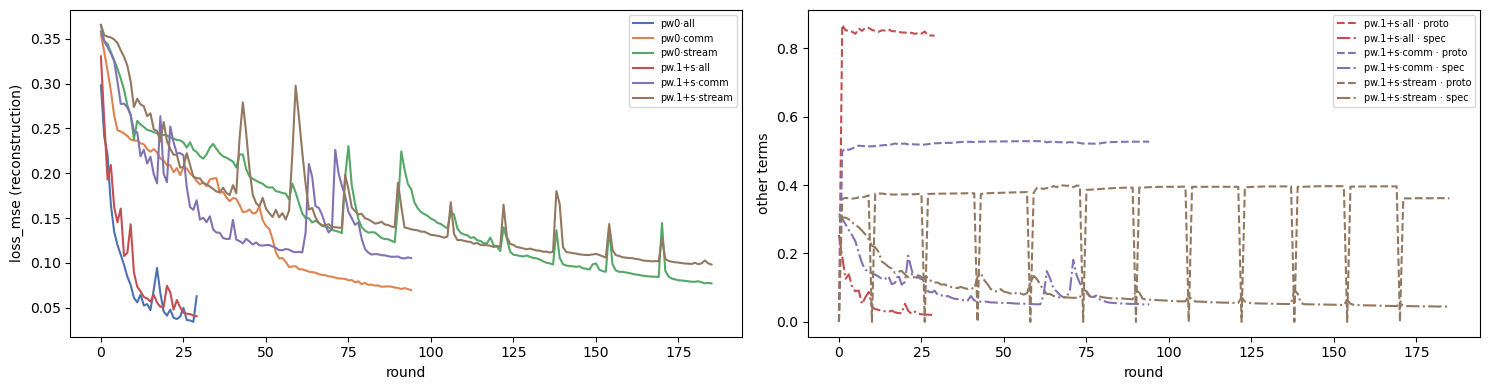

In [5]:
ALIGN24 = AL.Alignment(period_h=24, bin_h=None, block=1)
OUTS, SAN, MM = {}, {}, {}
for name in RUNS:
    OUTS[name] = AL.analyse(world, CELLS[name], ALIGN24, store=store, server=False, n_perm=99)
    SAN[name] = AL.sanity(world, OUTS[name], n_perm=99)
    ch = RC.channel_table(world, OUTS[name]["fw"])
    MM[name] = LE.model_matrix(world, OUTS[name], ch, store=store)
    SAN[name]["row"] = pd.concat([SAN[name]["row"], pd.Series(LE.lg_row(MM[name]))])
    assert OUTS[name]["checks"]["passed"].all()
    assert SAN[name]["control_check"]["passed"].all()

SANITY = pd.DataFrame({k: v["row"] for k, v in SAN.items()})
display(SANITY)

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
AL.plot_losses(ax, {k: OUTS[k]["res"]["training_log"] for k in OUTS})
fig.tight_layout()
plt.show()

## 4. Focus cell, and local vs global

`FOCUS` selects the cell the detailed sections read. The gap table and the model × client
matrices are v4's: rows are models (global, then each client's local weights), columns are the
client whose windows are reconstructed.

fbt__none+or__minmax_ref__a3w84s4__u30r95e5s0__Lp0.1-s1__C0-11


client,District_A,District_B,District_C,District_D,District_E
ratio_global,0.428,0.330,1.795,0.391,0.621
ratio_local,0.231,0.225,1.578,0.285,0.426
ratio_cross,0.668,0.647,2.073,0.682,0.893
amp_global,0.717,0.811,0.779,0.732,0.839
amp_local,0.885,0.926,0.901,0.891,0.861
amp_cross,0.719,0.770,0.822,0.767,0.927
r_global,0.589,0.850,0.489,0.666,0.589
r_local,0.740,0.917,0.478,0.733,0.602
r_cross,0.492,0.605,0.390,0.545,0.462
r_pure_global,NaN,NaN,NaN,NaN,NaN


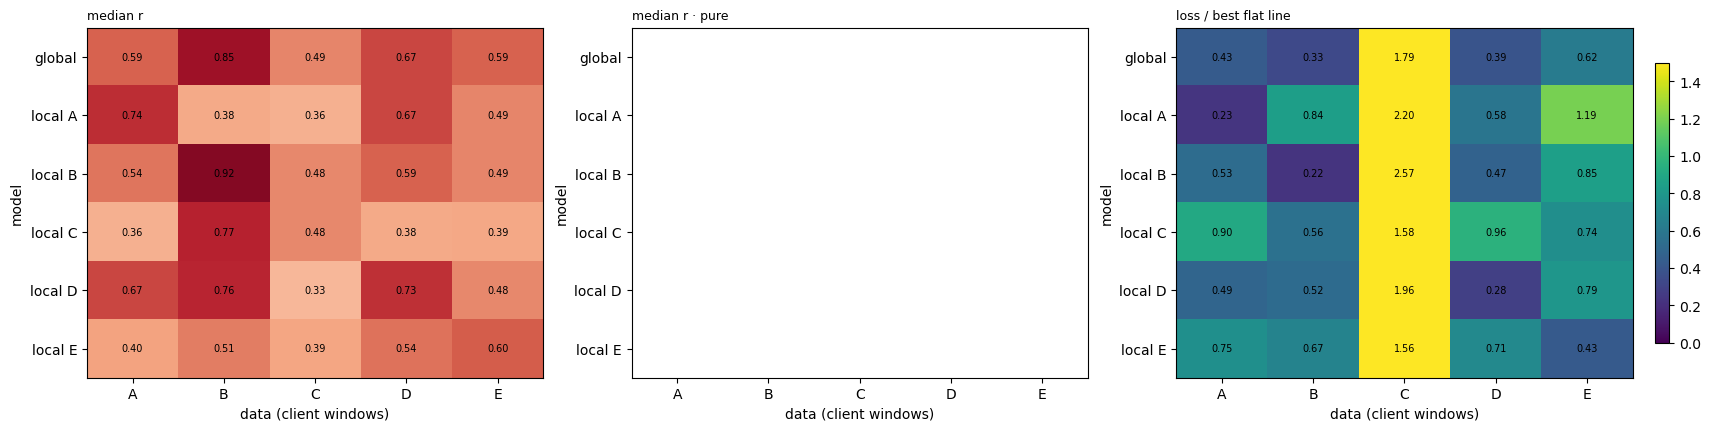

In [6]:
FOCUS = "pw.1+s·comm" #pw1.0+s·comm
out, san = OUTS[FOCUS], SAN[FOCUS]
run, ctrl, fw, model = out["run"], san["control"], out["fw"], out["model"]
channels = RC.channel_table(world, fw)
LOCAL = LE.local_runs(world, out, store=store)
mm = MM[FOCUS]
print(CELLS[FOCUS].label())

display(LE.gap_table(mm).set_index("client").round(3).T)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2), layout="constrained")
LE.plot_matrix(axes[0], mm, "r", title="median r")
LE.plot_matrix(axes[1], mm, "r_pure", title="median r · pure")
im = LE.plot_matrix(axes[2], mm, "ratio", vmin=0, vmax=1.5, cmap="viridis",
                    title="loss / best flat line")
fig.colorbar(im, ax=axes[2], shrink=0.8)
plt.show()

## 5. Window reconstruction

Per-window scores for the focus cell (global, local, untrained), then the month × start-class
grids and the position profiles. **Read the phase split:** a commissioning model is expected
to lose fidelity after the drift — that is the signal, not a failure.

pw0·all               pw0·comm               pw0·stream               pw.1+s·all               pw.1+s·comm               pw.1+s·stream              
                            r    amp   rmse        r    amp   rmse          r    amp   rmse          r    amp   rmse           r    amp   rmse             r    amp   rmse
phase      slot_class                                                                                                                                                     
final      branch       0.731  0.778  0.489    0.848  0.899  0.341      0.854  0.823  0.301      0.773  0.862  0.461       0.742  0.862  0.445         0.806  0.878  0.355
           transit      0.342  0.503  0.492    0.353  0.539  0.471      0.601  0.589  0.416      0.470  0.636  0.500       0.391  0.626  0.523         0.565  0.722  0.459
init       branch       0.565  0.764  0.500    0.903  0.909  0.268      0.839  0.801  0.344      0.741  0.854  0.451       0.789  0.832  0.373         0.806  0.851  0.397
           transit      0.327  0.513  0.483    0.587  0.534  0.451      0.531  0.582  0.428      0.462  0.651  0.485       0.438  0.640  0.464         0.502  0.689  0.467
transition branch       0.627  0.769  0.478    0.879  0.912  0.305      0.844  0.812  0.329      0.750  0.858  0.450       0.774  0.846  0.405         0.806  0.861  0.386
           transit      0.333  0.508  0.486    0.515  0.542  0.457      0.550  0.579  0.421      0.471  0.646  0.483       0.419  0.641  0.477         0.512  0.704  0.463

global         local       
                           r    amp      r    amp
client     slot_class                            
District_A branch      0.738  0.790  0.769  0.896
           transit     0.406  0.591  0.713  0.845
District_B branch      0.906  0.858  0.932  0.932
           transit     0.688  0.638  0.762  0.863
District_C branch      0.607  1.021  0.567  1.131
           transit     0.255  0.621  0.263  0.581
District_D branch      0.726  0.827  0.770  0.924
           transit     0.602  0.643  0.703  0.844
District_E branch      0.751  0.887  0.771  0.915
           transit     0.186  0.730  0.312  0.667

c:\Users\arthu\USPy\10_Mestrado\fedWater\notebooks\fedwater_lab_refactor\fedwater_lab\winrec.py:233: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  im = ax.imshow(piv.to_numpy(), aspect="auto", cmap=cmap, vmin=vmin,
c:\Users\arthu\USPy\10_Mestrado\fedWater\notebooks\fedwater_lab_refactor\fedwater_lab\winrec.py:233: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  im = ax.imshow(piv.to_numpy(), aspect="auto", cmap=cmap, vmin=vmin,
c:\Users\arthu\USPy\10_Mestrado\fedWater\notebooks\fedwater_lab_refactor\fedwater_lab\winrec.py:233: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  im = ax.imshow(piv.to_numpy(), aspect="auto", cmap=cmap, vmin=vmin,
c:\Users\arthu\USPy\10_Mestrado\fedWater\notebooks\fedwater_lab_refactor\fedwater_lab\winrec.py:233: UserWarning: Attempting to set identic

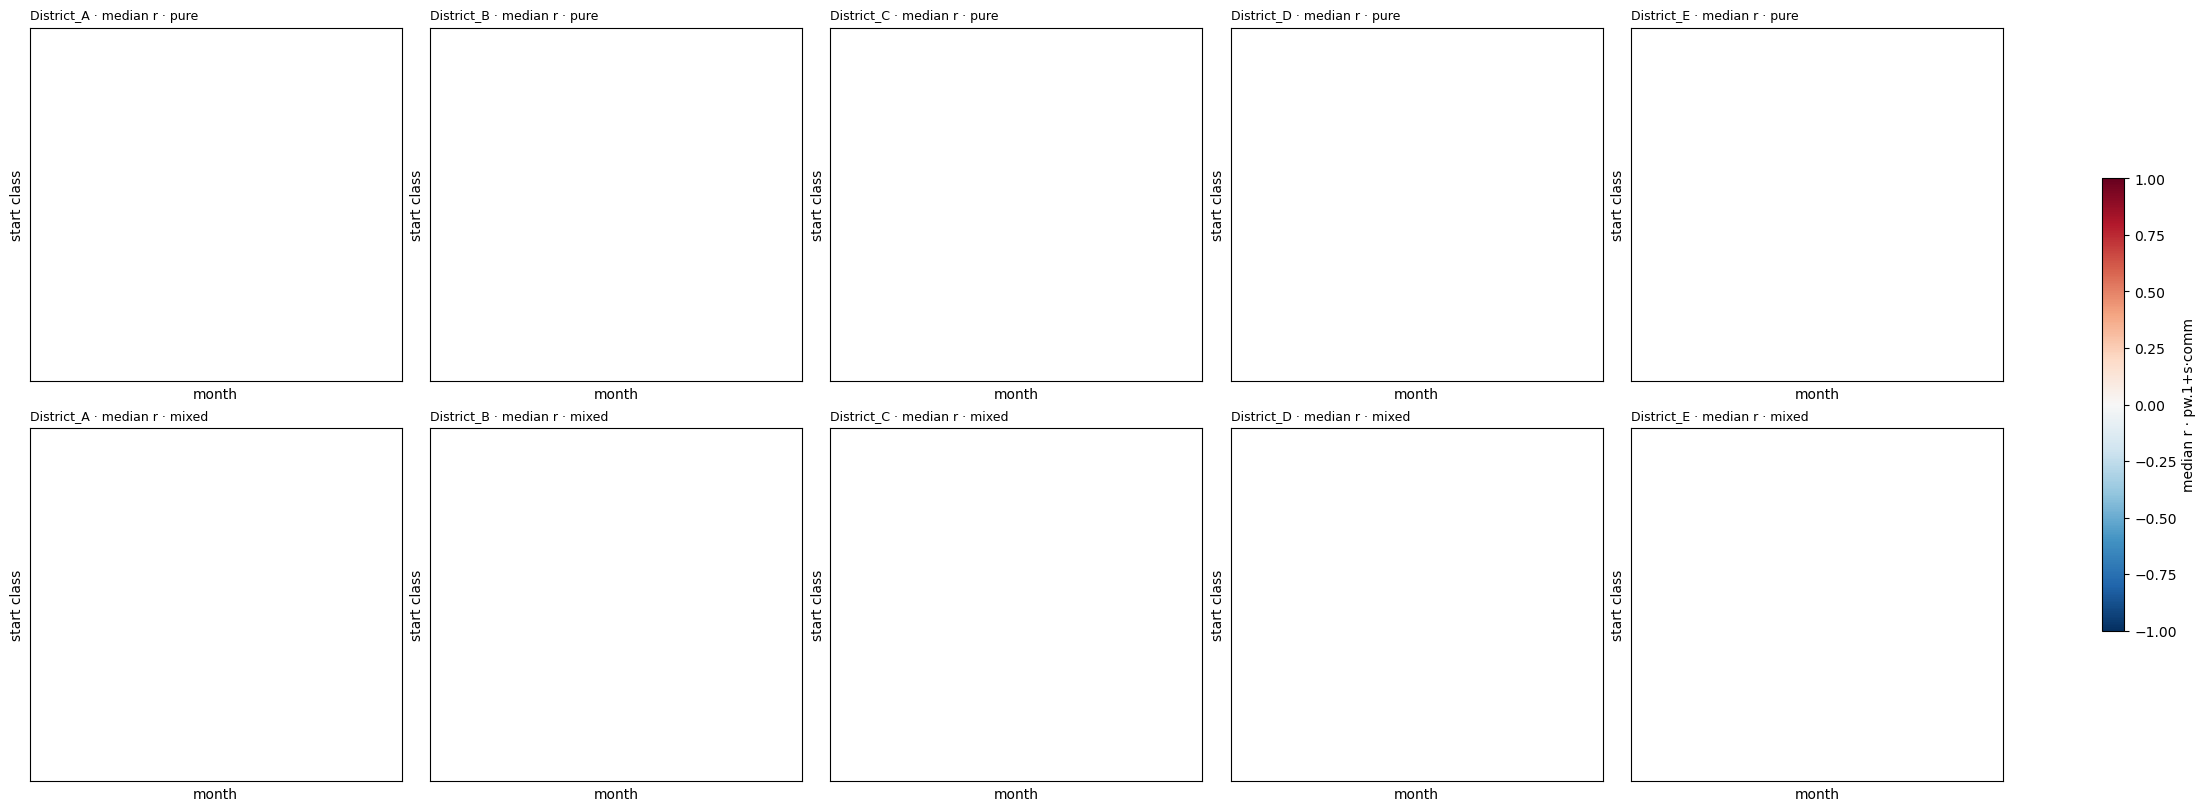

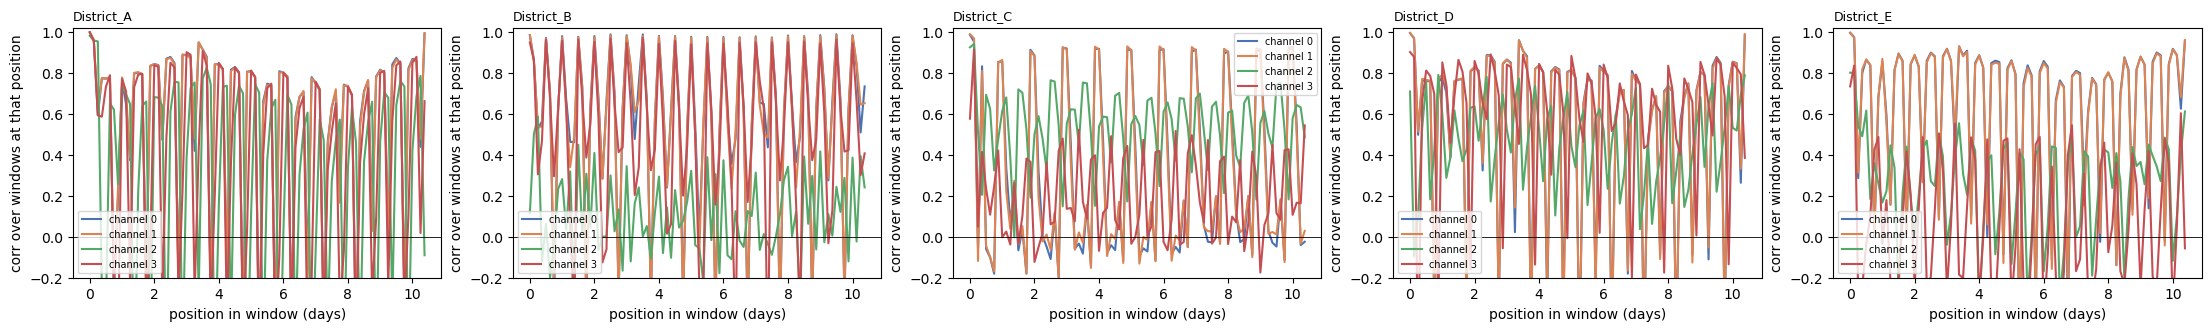

In [7]:
WS = {k: WR.window_scores(OUTS[k]["run"], OUTS[k]["fw"], channels) for k in OUTS}
display(pd.concat({k: v.groupby(["phase", "slot_class"])[["r", "amp", "rmse"]].median()
                   for k, v in WS.items()}, axis=1).round(3))

ws, ws_l = WS[FOCUS], pd.concat([WR.window_scores(LOCAL[c], {c: fw[c]}, channels)
                                 for c in LOCAL])
display(pd.concat({"global": ws.groupby(["client", "slot_class"])[["r", "amp"]].median(),
                   "local": ws_l.groupby(["client", "slot_class"])[["r", "amp"]].median()},
                  axis=1).round(3))

clients = world.client_names
fig, axes = plt.subplots(2, len(clients), figsize=(4.4 * len(clients), 8), squeeze=False,
                         layout="constrained")
for j, c in enumerate(clients):
    for i, cls in enumerate(("pure", "mixed")):
        im = WR.plot_score_grid(axes[i, j], ws, c, "r", cls)
fig.colorbar(im, ax=axes, shrink=0.6, label=f"median r · {FOCUS}")
plt.show()

fig, axes = plt.subplots(1, len(clients), figsize=(4.4 * len(clients), 3.2), squeeze=False,
                         layout="constrained")
for j, c in enumerate(clients):
    WR.plot_step_profile(axes[0, j], WR.step_profile(run, fw, c), run.agg_h, title=c)
plt.show()

In [8]:
BROWSE = "District_A"
_ = WR.window_browser(LOCAL[BROWSE], {BROWSE: fw[BROWSE]},
                      ws_l[ws_l["client"] == BROWSE], channels,
                      ctrl=run, ctrl_label="global model", run_label="local model")

## 6. Weekday × hour prototypes

Same key as v4 (`P=168`, pooled per phase). v4 found the weekly modulation missing from the
prototypes *because it is missing from the single-window reconstructions* (`ceiling` equals
`aligned`). The comparison below asks whether any schedule changes that: watch `amp` and
`r_shape` against `true`, and `r2_dem` (correlation with the district's own demand).

pw0·all                       pw0·comm                       pw0·stream                       pw.1+s·all                       pw.1+s·comm                       pw.1+s·stream                 \
                            rmse r_shape    amp r2_dem     rmse r_shape    amp r2_dem       rmse r_shape    amp r2_dem       rmse r_shape    amp r2_dem        rmse r_shape    amp r2_dem          rmse r_shape    amp   
source        phase                                                                                                                                                                                                      
true          init         0.000   1.000  1.000  0.702    0.000   1.000  1.000  0.702      0.000   1.000  1.000  0.702      0.000   1.000  1.000  0.702       0.000   1.000  1.000  0.702         0.000   1.000  1.000   
              transition   0.000   1.000  1.000  0.718    0.000   1.000  1.000  0.718      0.000   1.000  1.000  0.718      0.000   1.000  1.000  0.718       0.000   1.000  1.000  0.718         0.000   1.000  1.000   
              final        0.000   1.000  1.000  0.739    0.000   1.000  1.000  0.739      0.000   1.000  1.000  0.739      0.000   1.000  1.000  0.739       0.000   1.000  1.000  0.739         0.000   1.000  1.000   
aligned       init         0.460   0.488  0.683  0.305    0.338   0.708  0.752  0.562      0.370   0.663  0.716  0.495      0.426   0.605  0.805  0.407       0.393   0.648  0.781  0.431         0.399   0.647  0.815   
              transition   0.454   0.495  0.698  0.333    0.359   0.684  0.774  0.528      0.352   0.693  0.733  0.511      0.418   0.619  0.830  0.439       0.403   0.642  0.806  0.432         0.383   0.662  0.832   
              final        0.470   0.502  0.699  0.335    0.438   0.574  0.736  0.462      0.339   0.732  0.724  0.541      0.453   0.611  0.816  0.429       0.505   0.539  0.785  0.363         0.382   0.676  0.833   
ceiling       init         0.458   0.490  0.671  0.306    0.338   0.708  0.746  0.564      0.368   0.666  0.706  0.499      0.424   0.606  0.798  0.410       0.393   0.648  0.779  0.431         0.397   0.651  0.808   
              transition   0.449   0.501  0.682  0.336    0.351   0.696  0.735  0.548      0.346   0.700  0.709  0.519      0.414   0.622  0.811  0.445       0.404   0.642  0.789  0.431         0.378   0.667  0.820   
              final        0.469   0.503  0.690  0.337    0.438   0.575  0.731  0.463      0.338   0.732  0.719  0.542      0.452   0.611  0.810  0.430       0.504   0.539  0.784  0.363         0.381   0.676  0.830   
pooled        init         0.621   0.094  0.699  0.163    0.561   0.212  0.733  0.395      0.734  -0.074  0.884  0.196      0.689   0.008  0.821  0.158       0.534   0.223  0.648  0.349         0.559   0.214  0.667   
              transition   0.630   0.049  0.721  0.160    0.574   0.200  0.747  0.356      0.714  -0.061  0.886  0.191      0.675   0.017  0.838  0.198       0.547   0.217  0.679  0.300         0.556   0.212  0.667   
              final        0.641   0.068  0.722  0.228    0.637   0.140  0.708  0.306      0.711  -0.053  0.871  0.252      0.706   0.005  0.828  0.215       0.629   0.154  0.658  0.271         0.585   0.145  0.645   
ref_pooled    init         0.457   0.338  0.352  0.287    0.457   0.338  0.352  0.287      0.457   0.338  0.352  0.287      0.457   0.338  0.352  0.287       0.457   0.338  0.352  0.287         0.457   0.338  0.352   
              transition   0.456   0.327  0.344  0.232    0.456   0.327  0.344  0.232      0.456   0.327  0.344  0.232      0.456   0.327  0.344  0.232       0.456   0.327  0.344  0.232         0.456   0.327  0.344   
              final        0.478   0.261  0.279  0.161    0.478   0.261  0.279  0.161      0.478   0.261  0.279  0.161      0.478   0.261  0.279  0.161       0.478   0.261  0.279  0.161         0.478   0.261  0.279   
finch_aligned init         0.470   0.485  0.688  0.288    0.360   0.670  0.773  0.578      0.442   0.

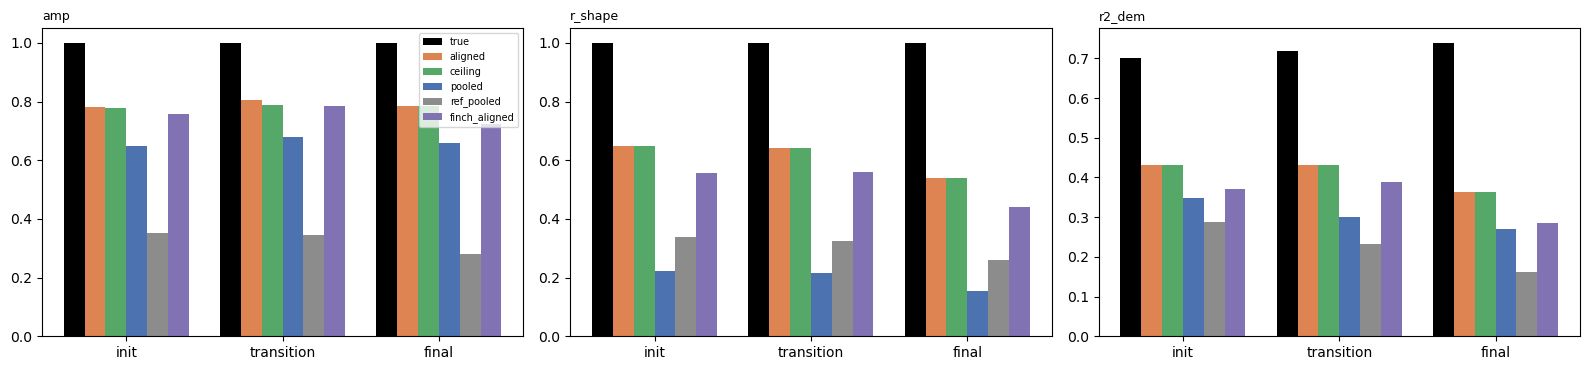

In [9]:
ALIGN168 = AL.Alignment(period_h=168, bin_h=None, block="phase")
OUT168 = {k: AL.analyse(world, CELLS[k], ALIGN168, store=store, server=True, n_perm=99)
          for k in RUNS}
display(pd.concat({k: v["summary"].set_index(["source", "phase"])[
    ["rmse", "r_shape", "amp", "r2_dem"]] for k, v in OUT168.items()}, axis=1).round(3))

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
AL.plot_ladder_summary(ax, OUT168[FOCUS]["summary"])
fig.tight_layout()
plt.show()

In [10]:
_ = AL.aligned_browser(OUT168[FOCUS]["run"], OUT168[FOCUS]["fid"], channels)

### 6b. Are the prototypes good enough for the NEXT step?

The downstream task measures dependence and similarity between clients. So score the
prototypes on exactly that, against the only yardstick available — the same quantity computed
from the raw data. Per calendar class $g$ and client pair $(c,d)$, over the selected channels:

* `s_true` $=\overline{\mathrm{corr}_t(T_{c,g,i}, T_{d,g,i})}$ — from the true class means;
* `s_dec` — the same on decoded prototypes;
* `s_lat` $=\cos(p_{c,g}, p_{d,g})$ — on the raw latent prototypes, which is what a federated
  dependence step would actually exchange.

`similarity_fidelity` reports, per phase and space: Pearson and Spearman against `s_true`, the
share of pair **orderings** preserved (`concordant` — the thing a ranking of dependencies
consumes), and the mean signed error (`s_lat` sits high because latents share a large common
direction, so its Spearman matters more than its level).

In [11]:
SIM = {k: CP.prototype_similarity(OUT168[k]["run"], channels, slot_class="pure")
       for k in RUNS}
FID = pd.concat({k: CP.similarity_fidelity(v) for k, v in SIM.items()}, names=["cell"])
display(FID.round(3))

# fig, axes = plt.subplots(1, 3, figsize=(16, 4), layout="constrained")
# for ax, ph in zip(axes, RC.PERIODS):
#     CP.plot_similarity(ax, SIM[FOCUS], "s_dec", ph)
# plt.show()

for name_exp, sim in SIM.items():
    fig, axes = plt.subplots(1, 3, figsize=(16, 4), layout="constrained")
    for ax, ph in zip(axes, RC.PERIODS):
        CP.plot_similarity(ax, sim, "s_dec", ph)
    fig.suptitle(name_exp)
    plt.show()

KeyError: 'phase'

## 7. Invariance across blocks

Per weekday·hour class, each 6-month block against the init reference (the block's own months
left out). `r_true` is the data side and is the same for every cell; `e_lat` and `r_dec` are
the representation, so they differ by schedule.

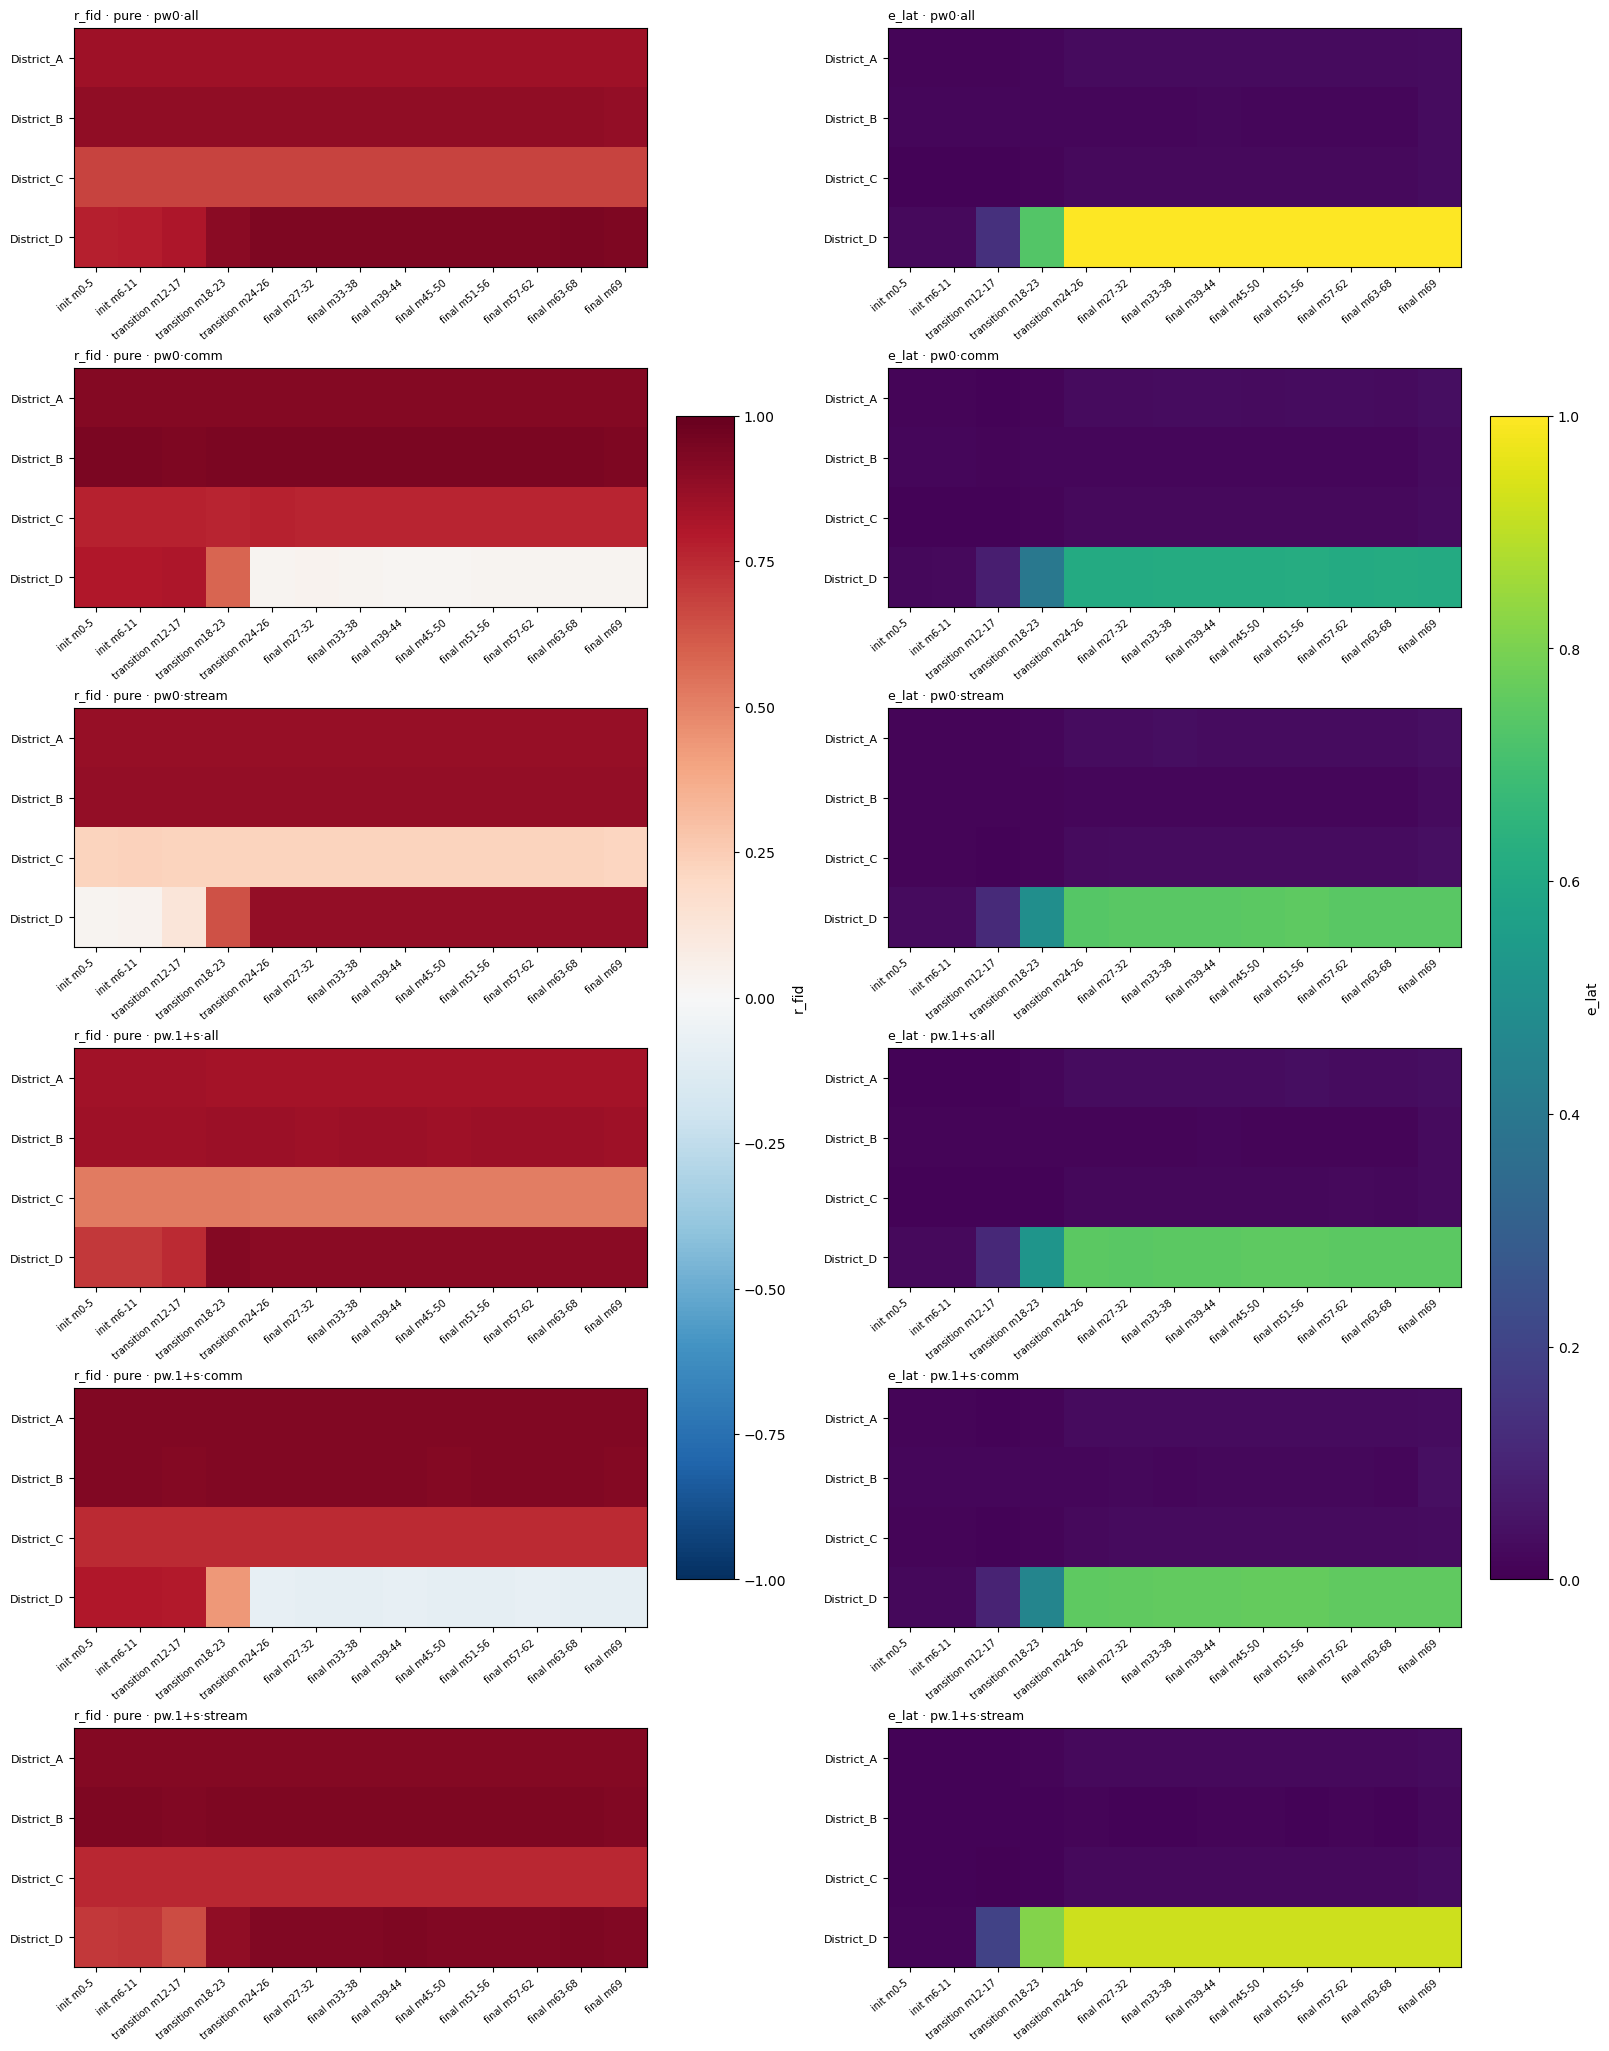

pw0·all                                                                     pw0·comm                                                                     pw0·stream         ... pw.1+s·all  \
                        e_lat                    r_fid                   r_true                      e_lat                    r_fid                   r_true                        e_lat         ...     r_true   
phase                   final   init transition  final   init transition  final   init transition    final   init transition  final   init transition  final   init transition      final   init  ...       init   
client     slot_class                                                                                                                                                                             ...              
District_A mixed        0.031  0.012      0.019  0.914  0.919      0.920  0.992  0.998      0.996    0.032  0.013      0.019  0.943  0.945      0.947  0.992  0.998      0.996      0.035  0.015  ...      0.998   
           pure         0.031  0.012      0.019  0.845  0.849      0.845  1.000  1.000      1.000    0.032  0.013      0.019  0.919  0.919      0.918  1.000  1.000      1.000      0.035  0.015  ...      1.000   
District_B mixed        0.020  0.017      0.017  0.912  0.912      0.914  0.994  0.998      0.997    0.019  0.016      0.016  0.937  0.938      0.939  0.994  0.998      0.997      0.018  0.015  ...      0.998   
           pure         0.020  0.017      0.017  0.886  0.887      0.886  0.999  0.999      0.999    0.019  0.016      0.016  0.938  0.939      0.938  0.999  0.999      0.999      0.018  0.015  ...      0.999   
District_C mixed        0.027  0.011      0.016  0.903  0.894      0.901  0.992  0.999      0.997    0.026  0.011      0.016  0.937  0.933      0.937  0.992  0.999      0.997      0.034  0.012  ...      0.999   
           pure         0.027  0.011      0.016  0.675  0.679      0.677  0.999  1.000      1.000    0.026  0.011      0.016  0.764  0.767      0.766  0.999  1.000      1.000      0.034  0.012  ...      1.000   
District_D mixed        1.282  0.026      0.716  0.896  0.292      0.607  0.968  0.999      0.987    0.614  0.023      0.366  0.370  0.916      0.678  0.968  0.999      0.987      0.746  0.029  ...      0.999   
           pure         1.282  0.026      0.716  0.936  0.779      0.883  0.279  0.999      0.610    0.614  0.023      0.366  0.027  0.801      0.471  0.279  0.999      0.610      0.746  0.029  ...      0.999   

                                 pw.1+s·comm                                                                     pw.1+s·stream                                                                      
                                       e_lat                    r_fid                   r_true                           e_lat                    r_fid                   r_true                    
phase                 transition       final   init transition  final   init transition  final   init transition         final   init transition  final   init transition  final   init transition  
client     slot_class                                                                                                                                                                               
District_A mixed           0.996       0.030  0.012      0.018  0.939  0.939      0.943  0.992  0.998      0.996         0.027  0.011      0.016  0.940  0.936      0.942  0.992  0.998      0.996  
           pure            1.000       0.030  0.012      0.018  0.928  0.929      0.928  1.000  1.000      1.000         0.027  0.011      0.016  0.916  0.916      0.916  1.000  1.000      1.000  
District_B mixed           0.997       0.023  0.018      0.019  0.893  0.895      0.896  0.994  0.998      0.997         0.013  0.010      0.011  0.917  0.913      0.918  0.994  0.998      0.997  
           pure            0.999       0.023  0.018      0.019  0.922  0.923      0.922  0.999  0.

In [ ]:
BLOCK = 6
INV = {k: AL.invariance(world, OUTS[k]["run"].wt, OUTS[k]["fw"], OUTS[k]["model"],
                        channels, block=BLOCK) for k in RUNS}
S_T = {k: AL.invariance_summary(v) for k, v in INV.items()}
INV_C = AL.invariance(world, san["control"].wt, fw, None, channels, block=BLOCK)

fig, axes = plt.subplots(len(S_T), 2, figsize=(16, 3.4 * len(S_T)), squeeze=False,
                         layout="constrained")
for i, (k, S) in enumerate(S_T.items()):
    im = AL.plot_invariance(axes[i, 0], S, "r_fid", "pure", vmin=-1, vmax=1)
    axes[i, 0].set_title(f"r_fid · pure · {k}", fontsize=9, loc="left")
    im2 = AL.plot_invariance(axes[i, 1], S, "e_lat", "pure", vmin=0, vmax=1, cmap="viridis")
    axes[i, 1].set_title(f"e_lat · {k}", fontsize=9, loc="left")
fig.colorbar(im, ax=axes[:, 0], shrink=0.6, label="r_fid")
fig.colorbar(im2, ax=axes[:, 1], shrink=0.6, label="e_lat")
plt.show()

display(pd.concat({k: v.pivot_table(index=["client", "slot_class"], columns="phase",
                                    values=["r_true", "r_fid", "e_lat"])
                   for k, v in S_T.items()}, axis=1).round(3))

## 8. Drift visibility — the comparison

Per (client, month), two signals from each cell:

* **reconstruction**: median `r` and `rmse` over that month's windows;
* **latent displacement**: `e_lat` $=\lVert z_m - z_{ref}\rVert / \lVert z_{ref}\rVert$ and
  `cos_lat`, against the client's own init mean latent.

`visibility` reduces each to one number,

$$z = \frac{\mathrm{median}_{post} - \mathrm{median}_{ref}}{\mathrm{IQR}_{ref}}$$

with `post` from `first_switch` on, and `r` negated so that positive always means "moved".
`contrast` is the drifting client's $z$ minus the largest of the others: **a schedule is good
for drift detection when contrast is large**, i.e. it moves for A and not for B, C, D.

For the streaming cell there is a stronger signal still: each block is scored **before** it is
trained on, so `prequential` is an out-of-sample curve over time, and the honest latents of
that moment are in `latent_trajectories_preq`.

--- z per client, signal = e_lat


,pw0·all,pw0·comm,pw0·stream,pw.1+s·all,pw.1+s·comm,pw.1+s·stream
client,,,,,,
District_A,4.64,6.41,5.81,8.65,4.35,3.18
District_B,0.41,0.65,0.51,0.40,0.52,0.34
District_C,2.80,4.88,3.43,3.04,5.81,4.28
District_D,89.03,51.50,40.70,70.20,58.21,130.25
contrast,84.39,45.10,34.89,61.56,52.40,125.97


--- z per client, signal = r


,pw0·all,pw0·comm,pw0·stream,pw.1+s·all,pw.1+s·comm,pw.1+s·stream
client,,,,,,
District_A,1.08,0.63,0.46,0.12,1.24,-0.57
District_B,-0.07,0.79,0.63,-0.08,0.15,0.70
District_C,1.91,1.52,0.51,0.99,1.30,-0.61
District_D,-22.32,192.23,-140.58,-20.94,125.11,-30.81
contrast,-24.23,190.71,-141.21,-21.93,123.81,-31.51


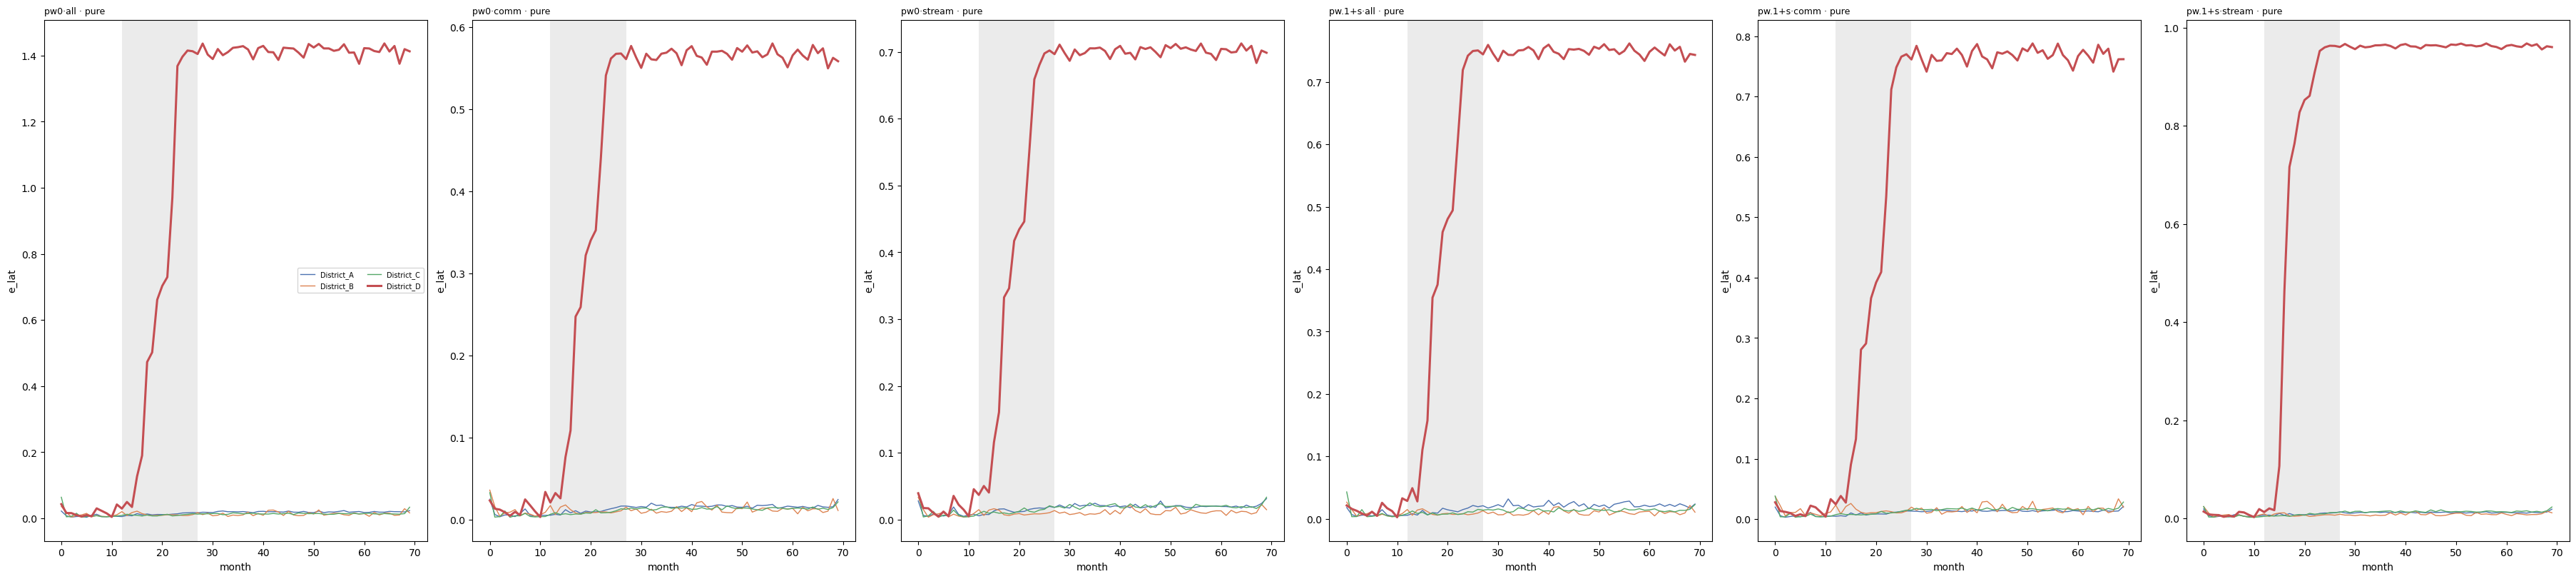

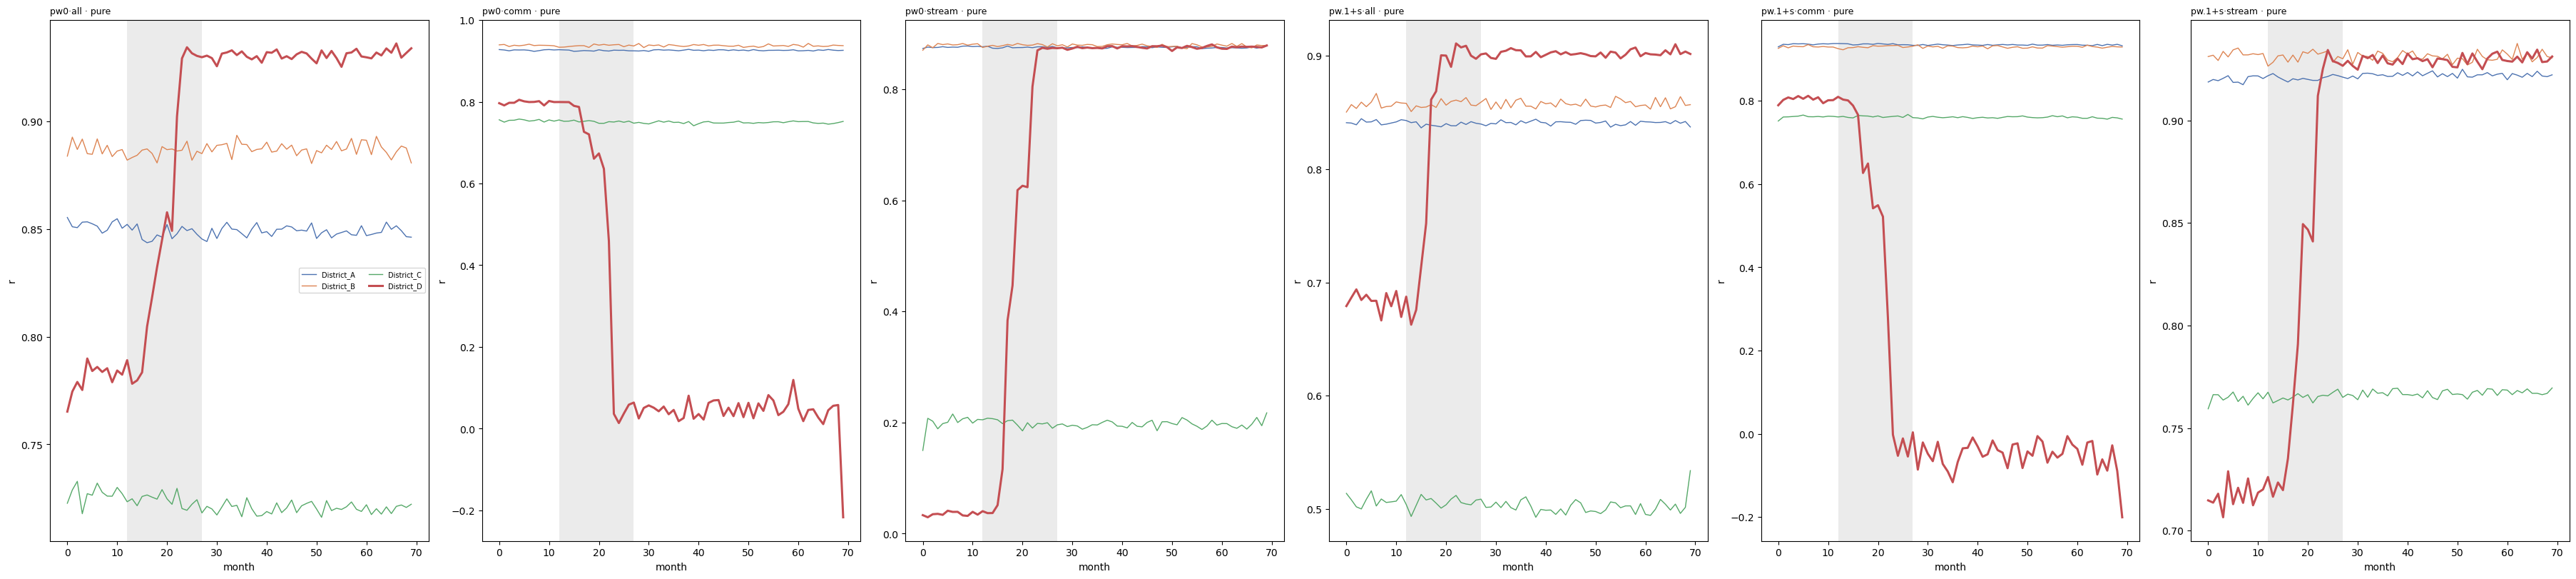

In [ ]:
PROF = {k: CP.drift_profile(world, OUTS[k]["run"], OUTS[k]["fw"], channels,
                            slot_class="pure") for k in RUNS}
VIS = {k: CP.visibility(PROF[k], world) for k in PROF}

for sig in ("e_lat", "r"):
    print(f"--- z per client, signal = {sig}")
    display(CP.compare_visibility(VIS, world, sig).round(2))

for sig in ("e_lat", "r"):
    fig, axes = plt.subplots(1, len(PROF), figsize=(6 * len(PROF), 8), squeeze=False,
                             layout="constrained")
    CP.plot_profiles(axes[0], PROF, world, sig, slot_note=" · pure")
    plt.show()

r         ratio       
model           global  local global  local
block m_lo m_hi                            
0     0    5    -0.027 -0.027  1.325  1.325
1     6    11   -0.005 -0.003  0.894  0.794
2     12   17    0.058  0.044  0.826  0.685
3     18   23    0.067  0.048  0.892  0.728
4     24   29    0.076  0.082  0.871  0.611
5     30   35    0.078  0.074  0.652  0.568
6     36   41    0.097  0.124  0.621  0.551
7     42   47    0.184  0.344  0.583  0.420
8     48   53    0.465  0.520  0.420  0.345
9     54   59    0.541  0.564  0.352  0.296
10    60   65    0.559  0.574  0.317  0.281
11    66   69    0.585  0.590  0.307  0.274

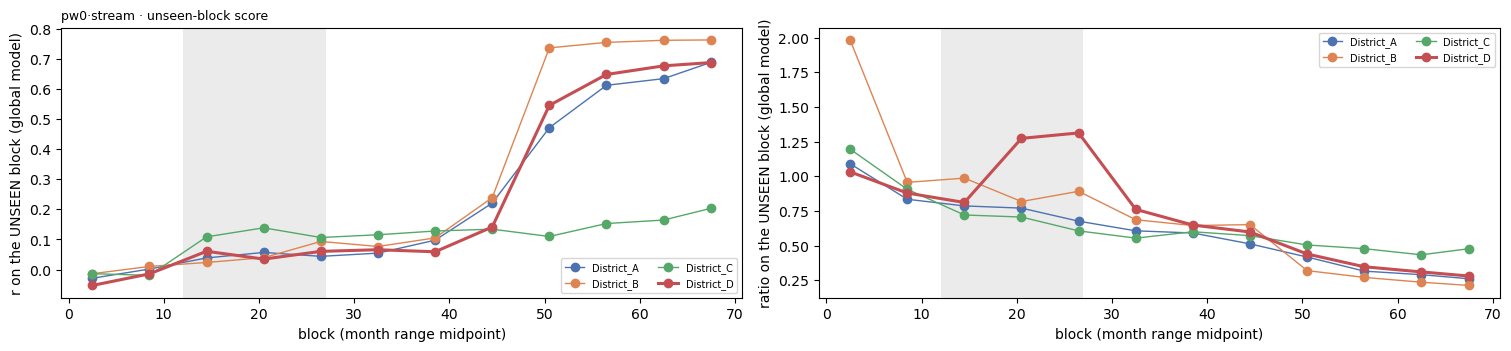

r         ratio       
model           global  local global  local
block m_lo m_hi                            
0     0    5    -0.027 -0.027  1.325  1.325
1     6    11   -0.018 -0.009  0.942  0.829
2     12   17    0.423  0.481  0.787  0.512
3     18   23    0.645  0.726  0.871  0.462
4     24   29    0.718  0.819  0.650  0.275
5     30   35    0.853  0.884  0.342  0.175
6     36   41    0.870  0.895  0.235  0.134
7     42   47    0.876  0.895  0.195  0.135
8     48   53    0.896  0.907  0.173  0.114
9     54   59    0.902  0.909  0.152  0.110
10    60   65    0.905  0.914  0.138  0.105
11    66   69    0.909  0.915  0.130  0.103

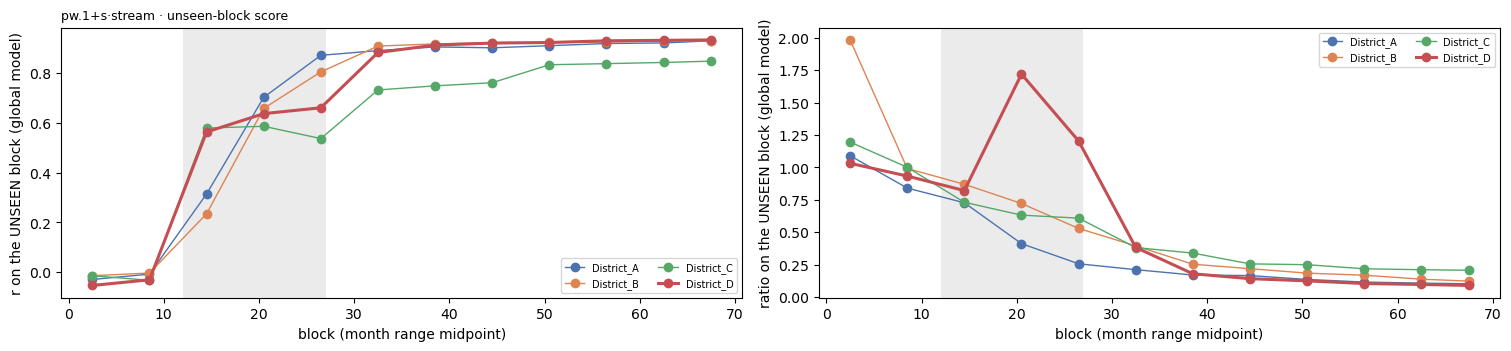

In [ ]:
STREAM_CELLS = [k for k in RUNS if OUTS[k]["res"].get("prequential") is not None]
for k in STREAM_CELLS:
    preq = OUTS[k]["res"]["prequential"]
    display(preq.pivot_table(index=["block", "m_lo", "m_hi"], columns="model",
                             values=["r", "ratio"]).round(3))
    fig, ax = plt.subplots(1, 2, figsize=(15, 3.4), layout="constrained")
    CP.plot_prequential(ax[0], preq, world, "r")
    CP.plot_prequential(ax[1], preq, world, "ratio")
    ax[0].set_title(f"{k} · unseen-block score", fontsize=9, loc="left")
    plt.show()

## What to read out of this

* **Which schedule wins on `contrast`?** That is the thesis-relevant number: drift visible in
  the drifting client, quiet elsewhere. The all-months model can absorb the drift (it trains
  on it), so the expectation is `comm` ≥ `stream` > `all` on reconstruction-based signals, and
  a smaller difference on latent displacement.
* **Fidelity is the counterweight.** A commissioning model should be the best on init months
  and the worst afterwards. If it is also worse on init (fewer windows, so fewer steps despite
  the matched budget), the comparison is about data volume, not the schedule.
* **Prequential is the only out-of-sample number here.** Everything else, in every cell, is
  in-sample.

**Open after this:**
* the weekend modulation is a fidelity gap, not an averaging one; the levers are a smaller
  stride, the spectral term, or explicit calendar conditioning of the decoder (upstream);
* bidirectional sensors need their own encoding (magnitude plus direction);
* `final` is one month in this world, so the post-drift side rests on the transition blocks;
* a world with distinct sector maps is still what the regime-recovery question needs.